# 02 — Cross-Cohort Biomarker Discovery: IBD (GSE75214) and Merged Cervical Cancer Cohorts

**Author:** Samuel Molina

This notebook compares two biomarker-discovery strategies:

- **Statistical pipeline** (in the style of Rosati et al., 2024): differential gene expression, FDR correction, visualization and single-gene ROC/AUC.
- **ML pipeline** (from notebook 01): multi-method feature selection (Mutual Information, RFECV, Elastic Net, Gradient Boosting) and classifier benchmarking.

**Part A** applies the statistical pipeline to the IBD cohort GSE75214 and handles class imbalance with weighted and boosted extreme learning machines.  
**Part B** integrates four public cervical-cancer GEO datasets from three microarray platforms (GSE6791, GSE9750, GSE63514, GSE67522) into one harmonized dataset and evaluates both pipelines on it.

> Originally developed for coursework (DANA 4830, Langara College) and extended as a portfolio project. See the repository README for known limitations.

## 0. Reproducibility and package information

This cell records package versions so the analysis can be replicated.

In [16]:

import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

RANDOM_STATE = 42

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.14.5
Platform: Windows-11-10.0.26200-SP0
NumPy: 2.4.5
Pandas: 3.0.3


# Part A — Biomarker Identification on GSE75214 (IBD)

**Goal:** identify IBD biomarkers with the statistical pipeline and compare them with the notebook 01 biomarkers.

## 1. Load GSE75214

Expected format:
- rows = samples
- columns = genes/features
- one label per sample


In [ ]:

geo_df = pd.read_csv(
    "GSE75214_series_matrix.txt",
    sep="\t",
    skiprows=66,
    low_memory=False
)

# Remove GEO end marker
geo_df = geo_df[geo_df["ID_REF"] != "!series_matrix_table_end"]

# Transpose: samples as rows and probes as columns
X_geo = geo_df.set_index("ID_REF").T.astype(float)

print("Expression matrix:", X_geo.shape)
display(X_geo.head())

Expression matrix: (194, 33252)


ID_REF,7892501,7892502,7892503,7892504,7892505,7892506,7892507,7892508,7892509,7892510,...,8180409,8180410,8180411,8180412,8180413,8180414,8180415,8180416,8180417,8180418
GSM1426071,3.097244,4.622620,4.588315,9.635181,4.524358,4.125697,5.024878,5.525576,10.967470,4.231957,...,9.958493,10.245059,8.623229,8.106611,8.105194,10.261790,6.833574,5.945972,7.913362,9.946090
GSM1426072,4.459059,4.866747,4.635416,8.897930,4.131027,4.444323,5.808175,4.546079,10.815401,3.943824,...,9.774100,10.464546,8.546375,8.348039,8.242692,10.769426,6.999750,5.603446,8.224295,10.662859
GSM1426073,3.322385,5.793462,7.472632,9.450976,4.633418,4.521593,5.067149,5.147985,9.640120,4.351993,...,8.960292,9.889874,6.911822,8.161219,8.112656,10.497715,6.665201,6.073405,8.193162,10.207571
GSM1426074,4.184156,5.652146,6.024110,8.800208,4.228925,5.214871,5.533964,5.590489,11.459983,4.798000,...,10.514199,10.765940,8.778329,8.443373,8.362471,10.774066,7.196679,5.239702,8.262609,10.451895
GSM1426075,3.567690,5.106890,4.213697,9.105323,4.757025,5.535967,5.146509,4.971026,10.617745,4.105912,...,9.869779,10.678419,7.974683,8.510100,8.446204,11.470899,6.852401,5.874210,8.353227,9.884931


In [ ]:
with open("GSE75214_series_matrix.txt") as f:
    metadata = [next(f).strip() for _ in range(66)]

disease = [x for x in metadata if "disease:" in x][0]
labels = disease.split("\t")[1:]
labels = [x.replace('"', '').replace("disease: ", "") for x in labels]

y_geo = pd.Series(labels, index=X_geo.index, name="Disease")

print(y_geo.value_counts())

Disease
ulcerative colitis    97
CD                    67
control               22
Crohn's disease        8
Name: count, dtype: int64


In [ ]:
y_geo = y_geo.replace({
    "ulcerative colitis": "IBD",
    "CD": "IBD",
    "Crohn's disease": "IBD",
    "control": "Control"
})

print(y_geo.value_counts())

Disease
IBD        172
Control     22
Name: count, dtype: int64


### Interpretation — dataset identity and dimensions

The GSE75214 dataset contains 194 samples and 33,252 expression probes.
The two biological groups compared in this analysis are patients with inflammatory bowel disease (IBD) and control samples. Ulcerative colitis and Crohn's disease samples were grouped into the IBD category.
The expression matrix contains 194 rows, which matches the 194 sample labels obtained from the dataset.

**Why this matters:** Before any statistical test, I verified that the dataset used here is GSE75214 and that the expression matrix and sample labels are aligned.

## 2. Initial quality-control inspection

This section checks missing values, data types, expression range, zeros, and class distribution before choosing any transformation.

In [17]:
print("Missing values:", X_geo.isna().sum().sum())

print("\nClass distribution:")
print(y_geo.value_counts())

print("\nExpression summary:")
print("Minimum:", X_geo.min().min())
print("Maximum:", X_geo.max().max())
print("Median:", np.median(X_geo.values))

Missing values: 0

Class distribution:
Disease
IBD        172
Control     22
Name: count, dtype: int64

Expression summary:
Minimum: 2.029952585
Maximum: 14.58024407
Median: 6.619168487


### Interpretation — quality control

No missing values were found in the expression matrix, so no imputation was required.
The dataset is imbalanced with 172 IBD samples and 22 control samples. This imbalance should be considered in the subsequent analysis.
Expression values ranged from approximately 2.03 to 14.58, with a median value of 6.62.
The expression values are already on a relatively compressed scale, suggesting that the data may have been previously transformed. Therefore, an additional log transformation was not applied to avoid unnecessarily transforming the data twice.

## 3. Preprocessing and normalization

The GSE75214 expression data were inspected before preprocessing to determine whether an additional transformation was necessary. 
Based on the expression range and the absence of missing values, no additional transformation was applied.


In [18]:
# Preprocessing
X_proc = X_geo.copy()

print("Processed matrix:", X_proc.shape)
print("Missing values:", X_proc.isna().sum().sum())

Processed matrix: (194, 33252)
Missing values: 0


### Interpretation — preprocessing decision
Based on the initial quality-control results, no additional transformation or missing-value imputation was applied. The expression values were already represented on a compressed scale and no missing values were detected. Therefore, the original expression matrix was retained for the differential expression analysis.

## 4. Encode labels and inspect imbalance

The statistical DGE comparison uses the biological groups directly. Numeric encoding is mainly needed for predictive evaluation.

In [19]:
le_geo = LabelEncoder()
y_geo_encoded = le_geo.fit_transform(y_geo)

geo_mapping = dict(zip(le_geo.classes_, le_geo.transform(le_geo.classes_)))

print("Label mapping:", geo_mapping)
print(pd.Series(y_geo_encoded).value_counts().sort_index())

Label mapping: {'Control': np.int64(0), 'IBD': np.int64(1)}
0     22
1    172
Name: count, dtype: int64


### Interpretation — class balance

The control group is the minority class with 22 samples compared with 172 IBD samples, showing a considerable class imbalance. This imbalance is important for predictive models because a model could favor the majority IBD class and still achieve high accuracy. For differential gene expression analysis, the original biological groups are retained because the objective is to compare the observed expression patterns between IBD and control samples.

## 5. Differential Gene Expression (DGE)

This section compares the two GSE75214 groups probe by probe using:
- Welch's two-sample t-test,
- Benjamini–Hochberg FDR correction,
- log2 fold change and effect direction.

Cutoff used in Part A: |log2FC| ≥ 1.0 and adjusted p < 0.05. Part B uses the stricter |log2FC| ≥ 1.5.

In [20]:
GROUP_A = "IBD"
GROUP_B = "Control"

LOGFC_CUTOFF = 1.0
PADJ_CUTOFF = 0.05


def run_dge(X, labels, group_a, group_b):

    labels = pd.Series(labels).reset_index(drop=True)
    X = X.reset_index(drop=True)

    mask_a = labels == group_a
    mask_b = labels == group_b

    results = []

    for probe in X.columns:

        a = X.loc[mask_a, probe]
        b = X.loc[mask_b, probe]

        # Welch's t-test
        stat, p = ttest_ind(a, b, equal_var=False)

        mean_a = a.mean()
        mean_b = b.mean()

        log2fc = mean_a - mean_b

        results.append([
            probe,
            mean_a,
            mean_b,
            log2fc,
            p
        ])

    dge = pd.DataFrame(
        results,
        columns=[
            "Probe",
            "Mean_IBD",
            "Mean_Control",
            "log2FC",
            "p_value"
        ]
    )

    # Benjamini-Hochberg FDR correction
    dge["adj_p_value"] = multipletests(
        dge["p_value"],
        method="fdr_bh"
    )[1]

    # Classify significant probes
    dge["Category"] = "Non-significant"

    dge.loc[
        (dge["log2FC"] >= LOGFC_CUTOFF) &
        (dge["adj_p_value"] < PADJ_CUTOFF),
        "Category"
    ] = "Upregulated"

    dge.loc[
        (dge["log2FC"] <= -LOGFC_CUTOFF) &
        (dge["adj_p_value"] < PADJ_CUTOFF),
        "Category"
    ] = "Downregulated"

    return dge.sort_values("adj_p_value")


dge21 = run_dge(
    X_proc,
    y_geo,
    GROUP_A,
    GROUP_B
)

print(dge21["Category"].value_counts())
display(dge21.head(20))

Category
Non-significant    32670
Upregulated          380
Downregulated        202
Name: count, dtype: int64


,Probe,Mean_IBD,Mean_Control,log2FC,p_value,adj_p_value,Category
9379,7948444,7.561290,5.059449,2.501841,9.788181e-41,3.254766e-36,Upregulated
33136,8180303,7.395929,4.711770,2.684159,3.750631e-39,6.235799e-35,Upregulated
12963,7983910,7.592938,5.044917,2.548022,7.673081e-39,8.504843e-35,Upregulated
30467,8156783,8.149672,6.928825,1.220847,7.753891e-37,6.445810e-33,Upregulated
23964,8095697,9.877600,7.538952,2.338648,2.719520e-36,1.808590e-32,Upregulated
6666,7922229,6.921558,5.070398,1.851160,3.384105e-34,1.875471e-30,Upregulated
31781,8169263,7.331459,4.913715,2.417745,2.729425e-32,1.247464e-28,Upregulated
11000,7965040,8.434301,7.018197,1.416104,3.001237e-32,1.247464e-28,Upregulated
24689,8102594,7.569026,5.144167,2.424859,7.257627e-32,2.681451e-28,Upregulated
5993,7915404,10.188308,12.418568,-2.230260,8.964684e-32,2.980937e-28,Downregulated


### Interpretation — DGE results
Using a |log2FC| cutoff of 1.0 and an adjusted p-value < 0.05, a total of 582 expressed probes were identified between IBD and control samples, 380 probes were upregulated and 202 were downregulated in IBD, while 32,670 probes did not meet both significance criteria. 
Among the strongest candidates were probes 7948444, 8180303, 7983910, 8095697, and 7915404, which showed large log2FC values and small adjusted p-values. This indicates that these probes presented both substantial expression differences and strong statistical significance between IBD and control samples. 
Adjusted p-values were used because thousands of probes were tested simultaneously, which increases the probability of false-positive results. Therefore, the Benjamini-Hochberg correction was applied to control the false discovery rate and provide more significant results.

## 6. Volcano plot

The volcano plot combines effect size and statistical significance. The interpretation below must describe **your actual figure**, not only define what a volcano plot is.

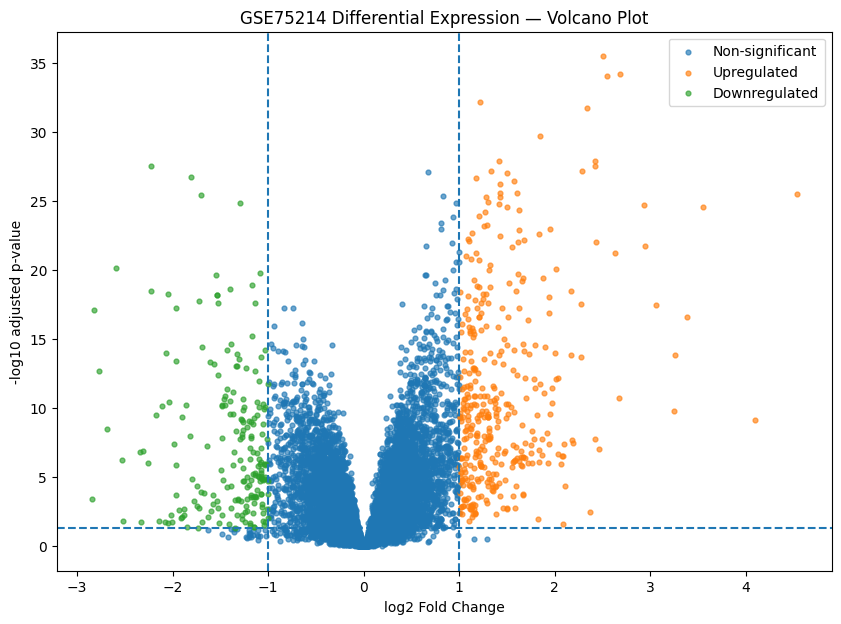

In [21]:
if 'dge21' in globals():
    vp = dge21.copy()
    vp["minus_log10_padj"] = -np.log10(vp["adj_p_value"].clip(lower=np.nextafter(0, 1)))

    plt.figure(figsize=(10, 7))

    for category in ["Non-significant", "Upregulated", "Downregulated"]:
        subset = vp[vp["Category"] == category]
        plt.scatter(
            subset["log2FC"],
            subset["minus_log10_padj"],
            s=12,
            alpha=0.65,
            label=category
        )

    plt.axvline(LOGFC_CUTOFF, linestyle="--")
    plt.axvline(-LOGFC_CUTOFF, linestyle="--")
    plt.axhline(-np.log10(PADJ_CUTOFF), linestyle="--")

    plt.xlabel("log2 Fold Change")
    plt.ylabel("-log10 adjusted p-value")
    plt.title("GSE75214 Differential Expression — Volcano Plot")
    plt.legend()
    plt.show()

### Interpretation — volcano plot
The volcano plot shows expressed probes in both directions between IBD and control samples. A larger number of probes were upregulated (380) than downregulated (202), consistent with the DGE results. Several probes showed both large absolute log2FC values and high statistical significance, appearing farther from zero and higher in the plot. Most probes remained within the log2FC thresholds and were classified as non-significant. Overall, the plot supports the presence of distinct expression changes between IBD and control samples.

## 7. Heatmap of top DEGs

Use the most significant genes to inspect whether their expression patterns separate the two biological groups.

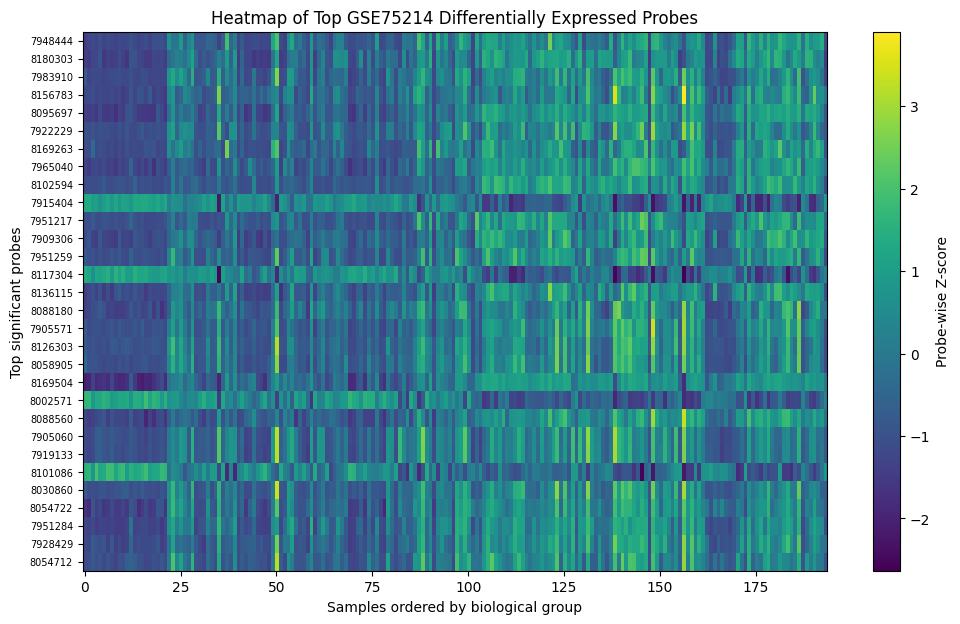

In [22]:
# Select the 30 most significant probes
top_probes = (
    dge21[dge21["Category"] != "Non-significant"]
    .head(30)["Probe"]
    .tolist()
)

# Expression values of selected probes
heat = X_proc[top_probes].copy()

# Z-score each probe across samples
heat_z = (heat - heat.mean()) / heat.std()

# Order samples by biological group
order = np.argsort(y_geo.astype(str).values)
heat_z = heat_z.iloc[order]

# Plot heatmap
plt.figure(figsize=(12, 7))
plt.imshow(
    heat_z.T,
    aspect="auto",
    interpolation="nearest"
)

plt.yticks(
    range(len(top_probes)),
    top_probes,
    fontsize=7
)

plt.xlabel("Samples ordered by biological group")
plt.ylabel("Top significant probes")
plt.title("Heatmap of Top GSE75214 Differentially Expressed Probes")
plt.colorbar(label="Probe-wise Z-score")

plt.show()

### Interpretation — heatmap


The heatmap shows different expression patterns between Control and IBD samples for the top 30 significant probes. Many probes show a clear change in standardized expression between the two biological groups. The heatmap supports the DGE results by showing that the most significant probes can distinguish the expression profiles of IBD and Control samples.

## 8. Candidate biomarkers from the Rosati-style pipeline

At this point, DGE identifies statistically strong candidates. Biological pathway evidence and diagnostic evaluation are then used to refine them.



In [23]:
candidate21 = dge21[dge21["Category"] != "Non-significant"].copy()

candidate21["abs_log2FC"] = candidate21["log2FC"].abs()

candidate21 = candidate21.sort_values(
    ["adj_p_value", "abs_log2FC"],
    ascending=[True, False]
).head(20)

display(candidate21)

,Probe,Mean_IBD,Mean_Control,log2FC,p_value,adj_p_value,Category,abs_log2FC
9379,7948444,7.561290,5.059449,2.501841,9.788181e-41,3.254766e-36,Upregulated,2.501841
33136,8180303,7.395929,4.711770,2.684159,3.750631e-39,6.235799e-35,Upregulated,2.684159
12963,7983910,7.592938,5.044917,2.548022,7.673081e-39,8.504843e-35,Upregulated,2.548022
30467,8156783,8.149672,6.928825,1.220847,7.753891e-37,6.445810e-33,Upregulated,1.220847
23964,8095697,9.877600,7.538952,2.338648,2.719520e-36,1.808590e-32,Upregulated,2.338648
6666,7922229,6.921558,5.070398,1.851160,3.384105e-34,1.875471e-30,Upregulated,1.851160
31781,8169263,7.331459,4.913715,2.417745,2.729425e-32,1.247464e-28,Upregulated,2.417745
11000,7965040,8.434301,7.018197,1.416104,3.001237e-32,1.247464e-28,Upregulated,1.416104
24689,8102594,7.569026,5.144167,2.424859,7.257627e-32,2.681451e-28,Upregulated,2.424859
5993,7915404,10.188308,12.418568,-2.230260,8.964684e-32,2.980937e-28,Downregulated,2.230260


### Interpretation — candidate biomarkers

The candidates were carried forward because they showed significant differential expression between IBD and Control, combining low adjusted p-values with substantial effect sizes.
The strongest statistical candidates included probes 7948444, 8180303, and 7983910, with adjusted p-values of approximately 3.25×10⁻³⁶, 6.24×10⁻³⁵, and 8.50×10⁻³⁵, respectively. Probe 8169504 also showed a particularly large effect size (log2FC = 4.53).
These probes are statistical biomarker candidates, but statistical significance alone does not demonstrate clinical utility. Further biological validation and diagnostic performance evaluation would be required before considering them clinically useful biomarkers.

## 10. ROC/AUC evaluation of individual candidate biomarkers

This estimates how well each candidate gene alone discriminates the two groups.

In [27]:
# ROC/AUC for candidate probes

y_binary = (y_geo == "IBD").astype(int)

auc_results = []

for probe in candidate21["Probe"]:
    auc = roc_auc_score(y_binary, X_proc[probe])
    auc_results.append([probe, max(auc, 1 - auc)])

biomarker_auc21 = pd.DataFrame(
    auc_results,
    columns=["Probe", "AUC"]
).sort_values("AUC", ascending=False)

display(biomarker_auc21)

,Probe,AUC
19,8169504,0.971459
3,8156783,0.956395
9,7915404,0.951110
4,8095697,0.949524
13,8117304,0.945032
7,7965040,0.940275
15,8088180,0.936047
0,7948444,0.918076
1,8180303,0.912791
5,7922229,0.911469


### Interpretation — biomarker ROC/AUC

Probe 8169504 had the highest AUC (0.971), indicating excellent discrimination between IBD and Control samples. Several other candidate probes also achieved AUC values above 0.90, supporting their potential as individual biomarkers. These AUC values were calculated using the same dataset used to identify the candidates. Therefore, they represent preliminary discriminatory performance and would require validation on independent data before claiming clinical biomarker utility.

## 11. Predictive evaluation with imbalance handling


In [28]:
# Prepare candidate probes for WELM / BWELM

model_probes = candidate21["Probe"].tolist()
X_model = X_proc[model_probes]
y_model = y_geo_encoded   # Control = 0, IBD = 1

# 60% train, 20% validation, 20% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X_model,
    y_model,
    test_size=0.40,
    stratify=y_model,
    random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

# Standardize using training data only
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print("Train:", X_train_s.shape)
print("Validation:", X_val_s.shape)
print("Test:", X_test_s.shape)

print("\nClass distribution:")
print("Train:", np.bincount(y_train))
print("Validation:", np.bincount(y_val))
print("Test:", np.bincount(y_test))

Train: (116, 20)
Validation: (39, 20)
Test: (39, 20)

Class distribution:
Train: [ 13 103]
Validation: [ 4 35]
Test: [ 5 34]


In [ ]:
class WELM:
    def __init__(self, n_hidden=200, C=1.0, random_state=42):
        self.n_hidden = n_hidden
        self.C = C
        self.random_state = random_state

    def _sigmoid(self, x):
        return 1 / (1 + np.exp(-np.clip(x, -30, 30)))

    def fit(self, X, y):
        rng = np.random.RandomState(self.random_state)

        self.W_in = rng.normal(
            size=(X.shape[1], self.n_hidden)
        )
        self.b = rng.normal(size=self.n_hidden)

        H = self._sigmoid(X @ self.W_in + self.b)

        # Give more weight to the minority class
        classes, counts = np.unique(y, return_counts=True)
        weight_map = {
            c: 1.0 / count
            for c, count in zip(classes, counts)
        }

        weights = np.array(
            [weight_map[label] for label in y]
        )

        T = np.where(y == 1, 1, -1).reshape(-1, 1)

        HtW = H.T * weights
        A = np.eye(self.n_hidden) / self.C + HtW @ H

        self.beta = np.linalg.solve(
            A,
            HtW @ T
        )

        return self

    def decision_function(self, X):
        H = self._sigmoid(X @ self.W_in + self.b)
        return (H @ self.beta).ravel()

    def predict(self, X):
        return (
            self.decision_function(X) > 0
        ).astype(int)

    def predict_proba(self, X):
        p = self._sigmoid(
            self.decision_function(X)
        )

        return np.column_stack([1 - p, p])

In [30]:
# Train WELM
welm = WELM(
    n_hidden=200,
    C=1.0,
    random_state=RANDOM_STATE
)

welm.fit(X_train_s, y_train)

# Validation predictions
y_val_pred = welm.predict(X_val_s)
y_val_prob = welm.predict_proba(X_val_s)[:, 1]

print("WELM — Validation results")
print("Accuracy:", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F1:", f1_score(y_val, y_val_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob))

print("\nClassification report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Control", "IBD"]
))

print("Confusion matrix:")
print(confusion_matrix(y_val, y_val_pred))

WELM — Validation results
Accuracy: 0.8461538461538461
Precision: 1.0
Recall: 0.8285714285714286
F1: 0.90625
ROC-AUC: 0.9642857142857143

Classification report:
              precision    recall  f1-score   support

     Control       0.40      1.00      0.57         4
         IBD       1.00      0.83      0.91        35

    accuracy                           0.85        39
   macro avg       0.70      0.91      0.74        39
weighted avg       0.94      0.85      0.87        39

Confusion matrix:
[[ 4  0]
 [ 6 29]]


In [31]:
class BWELM:
    def __init__(self, n_estimators=5, n_hidden=200, C=1.0, random_state=42):
        self.n_estimators = n_estimators
        self.n_hidden = n_hidden
        self.C = C
        self.random_state = random_state

    def _sigmoid(self, x):
        return 1 / (1 + np.exp(-np.clip(x, -30, 30)))

    def _fit_welm(self, X, y, sample_weight, seed):
        rng = np.random.RandomState(seed)

        W_in = rng.normal(size=(X.shape[1], self.n_hidden))
        b = rng.normal(size=self.n_hidden)

        H = self._sigmoid(X @ W_in + b)
        T = np.where(y == 1, 1, -1).reshape(-1, 1)

        HtW = H.T * sample_weight
        A = np.eye(self.n_hidden) / self.C + HtW @ H

        beta = np.linalg.solve(A, HtW @ T)

        return W_in, b, beta

    def _predict_welm(self, model, X):
        W_in, b, beta = model
        H = self._sigmoid(X @ W_in + b)

        return (H @ beta).ravel()

    def fit(self, X, y):
        classes, counts = np.unique(y, return_counts=True)
        m = len(classes)

        count_map = {
            c: count
            for c, count in zip(classes, counts)
        }

        # Initial class-balanced weights
        D = np.array([
            1.0 / (m * count_map[label])
            for label in y
        ])

        self.models = []
        self.alphas = []

        for t in range(self.n_estimators):

            model = self._fit_welm(
                X,
                y,
                D,
                self.random_state + t
            )

            pred = (
                self._predict_welm(model, X) > 0
            ).astype(int)

            correct = pred == y

            error = D[~correct].sum() / D.sum()
            error = np.clip(error, 1e-10, 1 - 1e-10)

            alpha = 0.5 * np.log(
                (1 - error) / error
            )

            self.models.append(model)
            self.alphas.append(alpha)

            # Update weights separately within each class
            for c in classes:
                idx = y == c

                D[idx & ~correct] *= np.exp(alpha)
                D[idx & correct] *= np.exp(-alpha)

                class_sum = D[idx].sum()

                if class_sum > 0:
                    D[idx] = D[idx] / class_sum / m

        return self

    def decision_function(self, X):
        total = np.zeros(X.shape[0])

        for model, alpha in zip(
            self.models,
            self.alphas
        ):
            total += alpha * np.sign(
                self._predict_welm(model, X)
            )

        return total

    def predict(self, X):
        return (
            self.decision_function(X) > 0
        ).astype(int)

    def predict_proba(self, X):
        decision = self.decision_function(X)

        scale = sum(
            abs(a) for a in self.alphas
        )

        p = self._sigmoid(
            decision / (scale + 1e-10) * 4
        )

        return np.column_stack([1 - p, p])

In [32]:
bwelm = BWELM(
    n_estimators=5,
    n_hidden=200,
    C=1.0,
    random_state=RANDOM_STATE
)

bwelm.fit(X_train_s, y_train)

y_val_pred_bw = bwelm.predict(X_val_s)
y_val_prob_bw = bwelm.predict_proba(X_val_s)[:, 1]

print("BWELM — Validation results")
print("Accuracy:", accuracy_score(y_val, y_val_pred_bw))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_bw))

print("\nClassification report:")
print(classification_report(
    y_val,
    y_val_pred_bw,
    target_names=["Control", "IBD"]
))

print("Confusion matrix:")
print(confusion_matrix(y_val, y_val_pred_bw))

BWELM — Validation results
Accuracy: 0.9487179487179487
ROC-AUC: 0.9714285714285714

Classification report:
              precision    recall  f1-score   support

     Control       0.67      1.00      0.80         4
         IBD       1.00      0.94      0.97        35

    accuracy                           0.95        39
   macro avg       0.83      0.97      0.89        39
weighted avg       0.97      0.95      0.95        39

Confusion matrix:
[[ 4  0]
 [ 2 33]]


### Note on WELM / BWELM

The weighted ELM and boosted weighted ELM implementations above were adapted from an earlier team assignment.

Weighting and boosting were used to address the strong class imbalance between Control and IBD samples. BWELM improved the validation performance compared with WELM, increasing accuracy from 0.846 to 0.949 and ROC-AUC from 0.964 to 0.971. Importantly, the minority Control class retained a recall of 1.00, while its precision improved from 0.40 to 0.67. The number of misclassified IBD samples also decreased from six to two. Therefore, BWELM provided better overall performance while preserving strong detection of the minority class.

## 12. Comparison with notebook 01 biomarkers


In [35]:
midterm_biomarkers = [
    "MMP11",
    "CA4",
    "COL10A1",
    "TSLP",
    "VEGFD",
    "C1QTNF9",
    "CAVIN2",
    "CD300LG",
    "CPA1",
    "CST1"
]

rosati_biomarkers21 = (
    biomarker_auc21["Probe"].head(10).astype(str).tolist()
    if 'biomarker_auc21' in globals()
    else (
        candidate21["Probe"].head(10).astype(str).tolist()
        if 'candidate21' in globals()
        else []
    )
)

comparison21 = pd.DataFrame({
    "Midterm_1": sorted(set(midterm_biomarkers) - set(rosati_biomarkers21)),
    "Rosati": sorted(set(rosati_biomarkers21) - set(midterm_biomarkers))
})

print("Overlap:", sorted(set(midterm_biomarkers) & set(rosati_biomarkers21)))
display(comparison21)

Overlap: []


,Midterm_1,Rosati
0,C1QTNF9,7915404
1,CA4,7922229
2,CAVIN2,7948444
3,CD300LG,7965040
4,COL10A1,8088180
5,CPA1,8095697
6,CST1,8117304
7,MMP11,8156783
8,TSLP,8169504
9,VEGFD,8180303


### Part A discussion

A direct overlap between the biomarkers from notebook 01 and the current analysis could not be determined because the notebook 01 biomarkers are represented as gene symbols, while the GSE75214 results are represented as microarray probe IDs. However, the two approaches differ mainly in their objective. The notebook 01 ML pipeline emphasized feature selection and machine learning to identify biomarkers with strong predictive value, while the current bioinformatics-oriented pipeline prioritized differential expression, statistical significance, visualization and individual ROC/AUC evaluation. Therefore, the approaches can be considered complementary, with one focusing more on prediction and the other on identifying biologically relevant expression differences.

### Part A conclusion

The GSE75214 analysis identified 582 differentially expressed probes between IBD and Control samples, including 380 upregulated and 202 downregulated probes. Several candidates showed strong differential expression and very low adjusted p-values, while individual ROC/AUC analysis identified probe 8169504 as the strongest discriminator, with an AUC of approximately 0.97. The predictive evaluation also showed that imbalance-aware methods performed well, with BWELM achieving approximately 0.95 validation accuracy and 0.97 ROC-AUC while maintaining perfect recall for the minority Control class. These results support the presence of strong expression-based signals capable of distinguishing IBD from Control samples. Direct overlap with the notebook 01 biomarkers could not be established because the notebook 01 results used gene symbols whereas the current GSE75214 analysis retained microarray probe IDs, but the two analyses provide complementary predictive and bioinformatics perspectives.

# Part B — Merging Four Cervical-Cancer GEO Datasets and Validating Both Pipelines

Datasets:
- GSE6791 (GPL570)
- GSE9750 (GPL96)
- GSE63514 (GPL570)
- GSE67522 (GPL10558)

DEG cutoff: **|log2FC| ≥ 1.5** and **adjusted p-value < 0.05**.

## 14. Load the four GEO datasets

Each dataset is prepared as samples × **gene symbols**, with a separate `Cancer` / `Normal` label. Probe IDs are never merged directly across platforms: each platform is mapped to gene symbols first.

In [45]:
import pandas as pd
from io import StringIO

datasets = ["GSE6791", "GSE9750", "GSE63514", "GSE67522"]

def load_series_matrix(gse):
    filename = f"{gse}_series_matrix.txt"

    # Find where the expression table begins and ends
    with open(filename, encoding="utf-8") as f:
        lines = f.readlines()

    start = next(
        i for i, line in enumerate(lines)
        if line.startswith("!series_matrix_table_begin")
    )

    end = next(
        i for i, line in enumerate(lines)
        if line.startswith("!series_matrix_table_end")
    )

    # Expression table is between those markers
    table_text = "".join(lines[start + 1:end])

    X = pd.read_csv(
        StringIO(table_text),
        sep="\t",
        index_col=0
    )

    # Remove quotes that GEO sometimes leaves in names
    X.index = X.index.astype(str).str.replace('"', '', regex=False)
    X.columns = X.columns.astype(str).str.replace('"', '', regex=False)

    return X


expression = {}

for gse in datasets:
    expression[gse] = load_series_matrix(gse)

    print(
        gse,
        "| probes:", expression[gse].shape[0],
        "| samples:", expression[gse].shape[1]
    )

GSE6791 | probes: 54675 | samples: 84
GSE9750 | probes: 22283 | samples: 66
GSE63514 | probes: 54675 | samples: 128
GSE67522 | probes: 42670 | samples: 42


In [47]:
def get_sample_metadata(gse):
    filename = f"{gse}_series_matrix.txt"

    metadata = []
    with open(filename, encoding="utf-8") as f:
        for line in f:
            if line.startswith("!series_matrix_table_begin"):
                break
            metadata.append(line.strip())

    def get_values(key):
        lines = [x for x in metadata if x.startswith(key)]
        if not lines:
            return []
        return [
            x.replace('"', '').strip()
            for x in lines[0].split("\t")[1:]
        ]

    samples = get_values("!Sample_geo_accession")
    titles = get_values("!Sample_title")
    sources = get_values("!Sample_source_name_ch1")

    # Combine all Sample_characteristics lines
    char_lines = [
        x for x in metadata
        if x.startswith("!Sample_characteristics_ch1")
    ]

    characteristics = [""] * len(samples)

    for line in char_lines:
        values = [
            x.replace('"', '').strip()
            for x in line.split("\t")[1:]
        ]

        for i, value in enumerate(values):
            characteristics[i] += " " + value

    return pd.DataFrame({
        "Sample": samples,
        "Title": titles,
        "Source": sources,
        "Characteristics": characteristics
    })


def classify_sample(row):
    text = (
        str(row["Title"]) + " " +
        str(row["Source"]) + " " +
        str(row["Characteristics"])
    ).lower()

    if "head and neck" in text:
        return "Exclude"

    if "cell line" in text:
        return "Exclude"

    if (
        "cin1" in text
        or "cin2" in text
        or "cin3" in text
        or "intraepithelial neoplas" in text
    ):
        return "Exclude"

    if "normal" in text:
        return "Normal"

    if (
        "cancer" in text
        or "carcinoma" in text
        or "cacner" in text
    ):
        return "Cancer"

    return "Exclude"


filtered_expression = {}
sample_metadata = {}

for gse in datasets:

    meta = get_sample_metadata(gse)
    meta["Label"] = meta.apply(classify_sample, axis=1)

    # Keep Cancer and Normal only
    meta = meta[meta["Label"].isin(["Cancer", "Normal"])].copy()

    # Match metadata samples with expression matrix columns
    valid_samples = [
        s for s in meta["Sample"]
        if s in expression[gse].columns
    ]

    meta = meta[meta["Sample"].isin(valid_samples)]

    filtered_expression[gse] = expression[gse][valid_samples]
    sample_metadata[gse] = meta

    print(
        gse,
        "| Cancer:", (meta["Label"] == "Cancer").sum(),
        "| Normal:", (meta["Label"] == "Normal").sum(),
        "| Total:", len(meta)
    )

GSE6791 | Cancer: 20 | Normal: 8 | Total: 28
GSE9750 | Cancer: 33 | Normal: 24 | Total: 57
GSE63514 | Cancer: 28 | Normal: 24 | Total: 52
GSE67522 | Cancer: 20 | Normal: 22 | Total: 42


In [48]:
for gse in datasets:
    filename = f"{gse}_series_matrix.txt"

    with open(filename, encoding="utf-8") as f:
        for line in f:
            if line.startswith("!Series_platform_id"):
                print(gse, "->", line.strip())
                break

GSE6791 -> !Series_platform_id	"GPL570"
GSE9750 -> !Series_platform_id	"GPL96"
GSE63514 -> !Series_platform_id	"GPL570"
GSE67522 -> !Series_platform_id	"GPL10558"


In [51]:
import GEOparse

platform_ids = ["GPL570", "GPL96", "GPL10558"]

gpls = {}

for gpl_id in platform_ids:
    print("Downloading:", gpl_id)
    gpls[gpl_id] = GEOparse.get_GEO(
        geo=gpl_id,
        destdir="./geo_platforms",
        silent=True
    )

    print(gpl_id, gpls[gpl_id].table.shape)

Downloading: GPL570


GPL570 (54675, 16)
Downloading: GPL96
GPL96 (22283, 16)
Downloading: GPL10558
GPL10558 (48107, 30)


In [55]:

platform_map = {
    "GSE6791":  ("GPL570", "Gene Symbol"),
    "GSE9750":  ("GPL96", "Gene Symbol"),
    "GSE63514": ("GPL570", "Gene Symbol"),
    "GSE67522": ("GPL10558", "Symbol")
}

gene_expression = {}

for gse, (gpl_id, symbol_col) in platform_map.items():

    # 1. Get platform annotation
    annot = gpls[gpl_id].table[["ID", symbol_col]].copy()

    annot = annot.rename(columns={
        "ID": "Probe",
        symbol_col: "Gene"
    })

    annot["Probe"] = annot["Probe"].astype(str)
    annot["Gene"] = annot["Gene"].astype(str).str.strip()

    # Remove probes without a valid gene symbol
    annot = annot[
        ~annot["Gene"].isin(["", "---", "nan", "NaN"])
    ].copy()

    # 2. Get filtered expression matrix
    X = filtered_expression[gse].copy()

    X.index = X.index.astype(str)

    # ID_REF contains the probe IDs
    X = X.reset_index().rename(
        columns={"ID_REF": "Probe"}
    )

    # 3. Match probes with gene symbols
    X = X.merge(
        annot,
        on="Probe",
        how="inner"
    )

    # 4. Put Gene first
    sample_cols = [
        col for col in X.columns
        if col not in ["Probe", "Gene"]
    ]

    # Make sure expression values are numeric
    X[sample_cols] = X[sample_cols].apply(
        pd.to_numeric,
        errors="coerce"
    )

    # 5. Average multiple probes mapping to the same gene
    X_gene = (
        X[["Gene"] + sample_cols]
        .groupby("Gene")
        .mean()
    )

    gene_expression[gse] = X_gene

    print(
        gse,
        "| mapped genes:", X_gene.shape[0],
        "| samples:", X_gene.shape[1]
    )

GSE6791 | mapped genes: 23520 | samples: 28
GSE9750 | mapped genes: 13515 | samples: 57
GSE63514 | mapped genes: 23520 | samples: 52
GSE67522 | mapped genes: 29148 | samples: 42


In [56]:
# Find genes shared by all four datasets

common_genes = set(gene_expression["GSE6791"].index)

for gse in ["GSE9750", "GSE63514", "GSE67522"]:
    common_genes = common_genes.intersection(
        gene_expression[gse].index
    )

common_genes = sorted(common_genes)

print("Common genes across all datasets:", len(common_genes))

Common genes across all datasets: 10783


### Interpretation — dataset acquisition

The four GEO datasets were generated using different microarray platforms, so probe IDs were mapped to gene symbols to obtain a common representation across datasets. When multiple probes mapped to the same gene, their expression values were averaged. After annotation, the intersection of gene symbols shared by all four datasets was retained, resulting in 10,783 common genes. Using this common gene set ensures that the subsequent merged analysis compares the same molecular features across all datasets and reduces inconsistencies caused by differences between microarray platforms.

## 15. Build the unified master dataset

The intersection of gene symbols shared by all four datasets is used as a conservative starting point. Dataset origin is kept as `Batch`. No batch-effect correction (e.g. ComBat) is applied; see Known limitations.

In [58]:
# ==========================================
# 15. Build unified master dataset
# ==========================================

master_parts = []

for gse in datasets:

    # Expression matrix:
    # currently genes x samples -> transpose to samples x genes
    X = common_expression[gse].T.copy()

    # Metadata for this dataset
    meta = sample_metadata[gse].copy()
    meta = meta.set_index("Sample")

    # Keep only samples present in both expression and metadata
    valid_samples = X.index.intersection(meta.index)

    X = X.loc[valid_samples].copy()
    meta = meta.loc[valid_samples].copy()

    # Add class label and dataset origin
    X["Label"] = meta["Label"]
    X["Batch"] = gse

    master_parts.append(X)


# Combine all datasets
master_df = pd.concat(master_parts, axis=0)

print("Master dataset shape:", master_df.shape)

print("\nSamples per dataset:")
print(master_df["Batch"].value_counts())

print("\nClass distribution:")
print(master_df["Label"].value_counts())

print("\nCancer/Normal by dataset:")
print(pd.crosstab(master_df["Batch"], master_df["Label"]))

Master dataset shape: (179, 10785)

Samples per dataset:
Batch
GSE9750     57
GSE63514    52
GSE67522    42
GSE6791     28
Name: count, dtype: int64

Class distribution:
Label
Cancer    101
Normal     78
Name: count, dtype: int64

Cancer/Normal by dataset:
Label     Cancer  Normal
Batch                   
GSE63514      28      24
GSE67522      20      22
GSE6791       20       8
GSE9750       33      24


### Interpretation — master dataset

The four cervical cancer GEO datasets were merged using the intersection of 10,783 gene symbols shared across all platforms. The resulting master dataset contained 179 samples, including 101 cancer and 78 normal samples. Dataset origin was retained in the Batch variable, with 28 samples from GSE6791, 57 from GSE9750, 52 from GSE63514, and 42 from GSE67522. This unified representation allows the datasets to be analyzed using a consistent set of molecular features while preserving information about their original study source.

## 16. DGE on the combined dataset

Thresholds: `|log2FC| ≥ 1.5` and `adjusted p-value < 0.05`.

In [61]:
# ==========================================
# Harmonize expression scale across datasets
# ==========================================

harmonized_expression = {}

for gse in datasets:

    X = common_expression[gse].copy()

    # These datasets are still on a linear expression scale
    if gse in ["GSE9750", "GSE67522"]:
        X = np.log2(X + 1)

    # GSE6791 and GSE63514 are already log2-transformed
    harmonized_expression[gse] = X

    print(
        gse,
        "| Min:", round(X.min().min(), 3),
        "| Median:", round(np.median(X.values), 3),
        "| Max:", round(X.max().max(), 3)
    )

GSE6791 | Min: 3.417 | Median: 7.636 | Max: 14.721
GSE9750 | Min: 0.0 | Median: 6.698 | Max: 16.019
GSE63514 | Min: 0.559 | Median: 5.403 | Max: 16.801
GSE67522 | Min: 4.519 | Median: 6.288 | Max: 14.33


In [62]:
# ==========================================
# Rebuild harmonized master dataset
# ==========================================

master_parts = []

for gse in datasets:

    # genes x samples -> samples x genes
    X = harmonized_expression[gse].T.copy()

    meta = sample_metadata[gse].copy()
    meta = meta.set_index("Sample")

    valid_samples = X.index.intersection(meta.index)

    X = X.loc[valid_samples].copy()
    meta = meta.loc[valid_samples].copy()

    X["Label"] = meta["Label"]
    X["Batch"] = gse

    master_parts.append(X)

master_df = pd.concat(master_parts, axis=0)

print("Master dataset shape:", master_df.shape)
print("\nClass distribution:")
print(master_df["Label"].value_counts())

print("\nSamples by batch and class:")
print(pd.crosstab(master_df["Batch"], master_df["Label"]))

Master dataset shape: (179, 10785)

Class distribution:
Label
Cancer    101
Normal     78
Name: count, dtype: int64

Samples by batch and class:
Label     Cancer  Normal
Batch                   
GSE63514      28      24
GSE67522      20      22
GSE6791       20       8
GSE9750       33      24


In [63]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

# ==========================================
# 16. DGE on combined dataset
# Required thresholds:
# |logFC| >= 1.5
# adjusted p-value < 0.05
# ==========================================

TASK22_LOGFC_CUTOFF = 1.5
TASK22_PADJ_CUTOFF = 0.05

gene_cols = common_genes

# Separate the two biological groups
cancer = master_df.loc[
    master_df["Label"] == "Cancer",
    gene_cols
]

normal = master_df.loc[
    master_df["Label"] == "Normal",
    gene_cols
]

results = []

for gene in gene_cols:

    cancer_values = cancer[gene].astype(float)
    normal_values = normal[gene].astype(float)

    # Since expression is already on log2 scale,
    # difference in means = log2 fold change
    log2FC = cancer_values.mean() - normal_values.mean()

    # Welch's t-test
    stat, p_value = ttest_ind(
        cancer_values,
        normal_values,
        equal_var=False,
        nan_policy="omit"
    )

    results.append([
        gene,
        cancer_values.mean(),
        normal_values.mean(),
        log2FC,
        p_value
    ])

# Build results table
dge22 = pd.DataFrame(
    results,
    columns=[
        "Gene",
        "Mean_Cancer",
        "Mean_Normal",
        "log2FC",
        "p_value"
    ]
)

# Replace missing p-values conservatively
dge22["p_value"] = dge22["p_value"].fillna(1.0)

# Benjamini-Hochberg multiple-testing correction
dge22["adj_p_value"] = multipletests(
    dge22["p_value"],
    method="fdr_bh"
)[1]

# Classify genes using REQUIRED thresholds
dge22["Category"] = "Non-significant"

dge22.loc[
    (dge22["log2FC"] >= TASK22_LOGFC_CUTOFF) &
    (dge22["adj_p_value"] < TASK22_PADJ_CUTOFF),
    "Category"
] = "Upregulated"

dge22.loc[
    (dge22["log2FC"] <= -TASK22_LOGFC_CUTOFF) &
    (dge22["adj_p_value"] < TASK22_PADJ_CUTOFF),
    "Category"
] = "Downregulated"

# Sort by adjusted p-value
dge22 = dge22.sort_values(
    "adj_p_value"
).reset_index(drop=True)

print("DGE results:")
print(dge22["Category"].value_counts())

print("\nTop 30 genes:")
display(dge22.head(30))

DGE results:
Category
Non-significant    10462
Upregulated          165
Downregulated        156
Name: count, dtype: int64

Top 30 genes:


,Gene,Mean_Cancer,Mean_Normal,log2FC,p_value,adj_p_value,Category
0,CDKN2A,8.533215,5.339080,3.194135,2.785807e-43,3.003936e-39,Upregulated
1,KIF14,8.333769,5.659250,2.674519,4.874223e-36,2.627937e-32,Upregulated
2,CRNN,5.518357,12.620428,-7.102071,3.862922e-33,1.388463e-29,Downregulated
3,NEK2,7.524158,5.587694,1.936465,2.150235e-32,5.796497e-29,Upregulated
4,SMC4,9.569345,7.714777,1.854568,6.334500e-32,1.366098e-28,Upregulated
5,MAL,7.473256,12.886436,-5.413180,4.935346e-31,8.869639e-28,Downregulated
6,ATAD2,8.230297,6.075390,2.154907,3.479748e-29,4.690265e-26,Upregulated
7,KNTC1,9.269992,6.854659,2.415333,3.208847e-29,4.690265e-26,Upregulated
8,SYCP2,6.484276,3.943674,2.540602,1.043872e-28,1.250675e-25,Upregulated
9,CENPF,7.955441,6.166558,1.788882,7.292751e-27,7.214710e-24,Upregulated


### Interpretation — Part B DEGs

Differential expression analysis of the combined cervical cancer dataset identified 321 significant DEGs using the required thresholds of |log2FC| ≥ 1.5 and adjusted p-value < 0.05. Of these, 165 genes were upregulated and 156 were downregulated in cancer samples relative to normal samples, indicating substantial transcriptional differences between the two groups. CDKN2A was the most statistically significant gene and showed strong upregulation in cancer (log2FC = 3.19), while genes such as CRNN and MAL showed strong downregulation. These results provide a set of cross-dataset candidate genes for subsequent biomarker validation

## 17. Volcano plot — Part B

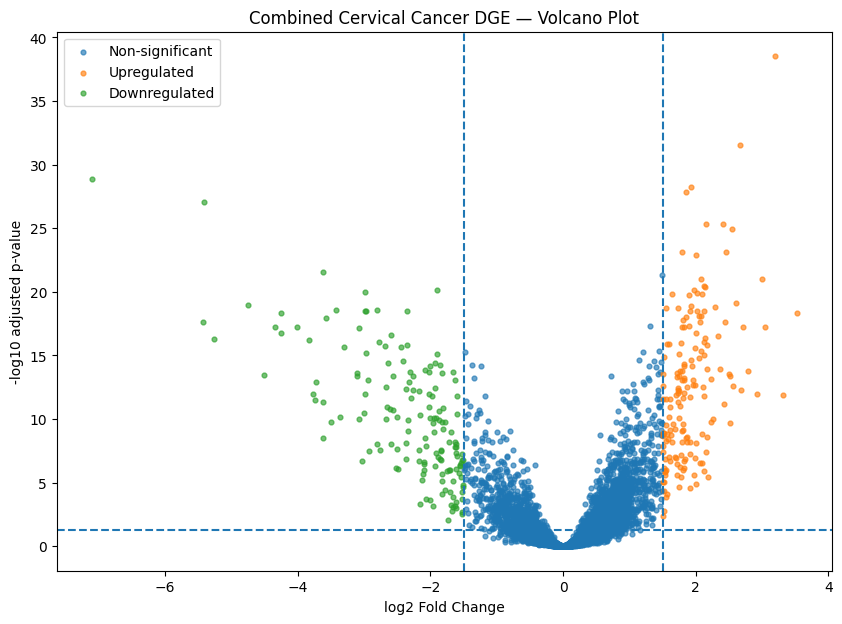

In [64]:

volcano22 = dge22.copy()

# Avoid log10(0)
volcano22["minus_log10_padj"] = -np.log10(
    volcano22["adj_p_value"].clip(lower=np.nextafter(0, 1))
)

plt.figure(figsize=(10, 7))

for category in ["Non-significant", "Upregulated", "Downregulated"]:
    subset = volcano22[volcano22["Category"] == category]

    plt.scatter(
        subset["log2FC"],
        subset["minus_log10_padj"],
        s=12,
        alpha=0.65,
        label=category
    )

# Required thresholds
plt.axvline(1.5, linestyle="--")
plt.axvline(-1.5, linestyle="--")
plt.axhline(-np.log10(0.05), linestyle="--")

plt.xlabel("log2 Fold Change")
plt.ylabel("-log10 adjusted p-value")
plt.title("Combined Cervical Cancer DGE — Volcano Plot")
plt.legend()

plt.show()

### Interpretation — Part B volcano plot
The volcano plot shows clear differential expression between cervical cancer and normal samples using the required thresholds of |log2FC| ≥ 1.5 and adjusted p-value < 0.05. A total of 321 genes met both criteria, including 165 upregulated and 156 downregulated genes in cancer. Significant genes are present on both sides of the plot, indicating substantial increases and decreases in gene expression associated with cervical cancer.Several genes also show very high statistical significance, supporting the presence of  expression differences between cancer and normal samples in the combined dataset.

## 18. Validate Pipeline 1 — Rosati-style bioinformatics pipeline


In [ ]:
rosati_candidates_to_validate = (
    dge22[
        dge22["Category"].isin(["Upregulated", "Downregulated"])
    ]
    .sort_values("adj_p_value")
    .head(10)["Gene"]
    .tolist()
)

# Keep only genes available in the master dataset
available_rosati22 = [
    g for g in rosati_candidates_to_validate
    if g in master_df.columns
]

print("Rosati-style candidates selected:")
print(rosati_candidates_to_validate)

print("\nCandidates available in master dataset:")
print(available_rosati22)

Rosati-style candidates selected:
['CDKN2A', 'KIF14', 'CRNN', 'NEK2', 'SMC4', 'MAL', 'ATAD2', 'KNTC1', 'SYCP2', 'CENPF']

Candidates available in master dataset:
['CDKN2A', 'KIF14', 'CRNN', 'NEK2', 'SMC4', 'MAL', 'ATAD2', 'KNTC1', 'SYCP2', 'CENPF']


In [ ]:
from sklearn.metrics import roc_auc_score

validation_rows = []

# Binary outcome: Cancer = 1, Normal = 0
y_binary = (master_df["Label"] == "Cancer").astype(int)

for gene in available_rosati22:

    # Get DGE information already calculated
    row = dge22[dge22["Gene"] == gene].iloc[0]

    log2fc = row["log2FC"]
    padj = row["adj_p_value"]
    category = row["Category"]

    # Expression values
    values = master_df[gene].astype(float)

    # Raw AUC
    raw_auc = roc_auc_score(y_binary, values)

    # Orientation-independent discrimination
    discrimination_auc = max(raw_auc, 1 - raw_auc)

    validation_rows.append({
        "Gene": gene,
        "log2FC": log2fc,
        "Adjusted_p": padj,
        "Direction": category,
        "Raw_AUC": raw_auc,
        "Discrimination_AUC": discrimination_auc
    })

rosati_validation22 = pd.DataFrame(validation_rows)

rosati_validation22 = rosati_validation22.sort_values(
    "Discrimination_AUC",
    ascending=False
).reset_index(drop=True)

display(rosati_validation22)

,Gene,log2FC,Adjusted_p,Direction,Raw_AUC,Discrimination_AUC
0,CDKN2A,3.194135,3.003936e-39,Upregulated,0.961538,0.961538
1,KIF14,2.674519,2.627937e-32,Upregulated,0.949860,0.949860
2,NEK2,1.936465,5.796497e-29,Upregulated,0.935453,0.935453
3,SMC4,1.854568,1.366098e-28,Upregulated,0.924727,0.924727
4,CENPF,1.788882,7.214710e-24,Upregulated,0.919396,0.919396
5,CRNN,-7.102071,1.388463e-29,Downregulated,0.081874,0.918126
6,KNTC1,2.415333,4.690265e-26,Upregulated,0.916730,0.916730
7,ATAD2,2.154907,4.690265e-26,Upregulated,0.915461,0.915461
8,MAL,-5.413180,8.869639e-28,Downregulated,0.093171,0.906829
9,SYCP2,2.540602,1.250675e-25,Upregulated,0.901498,0.901498


### Interpretation — Rosati-style validation

All ten Rosati-style candidates were available in the harmonized master dataset: CDKN2A, KIF14, CRNN, NEK2, SMC4, MAL, ATAD2, KNTC1, SYCP2, and CENPF.
All ten candidates retained significant differential expression under the required thresholds (|log2FC| ≥ 1.5 and adjusted p-value < 0.05). Eight candidates were upregulated in cervical cancer, while CRNN and MAL were strongly downregulated.
All ten candidates showed strong individual discrimination between cancer and normal samples, with discrimination AUC values above 0.90. CDKN2A showed the highest AUC (0.962), followed by KIF14 (0.950) and NEK2 (0.935). The downregulated genes CRNN and MAL also showed strong orientation-independent discrimination, with AUC values of 0.918 and 0.907, respectively.

These results validate the Rosati-style pipeline methodology rather than the transferability of IBD-specific biomarkers to cervical cancer. Because IBD and cervical cancer are biologically distinct diseases, biomarkers identified for IBD should not be expected to retain the same expression patterns or predictive value in cervical cancer. Disease-specific candidate genes were selected from the cervical-cancer analysis while preserving the same differential-expression and ROC/AUC validation framework.

## 19. Validate Pipeline 2 — ML pipeline from notebook 01

Applied to the combined cervical-cancer master dataset:
1. significant DEG subset,
2. train/test split,
3. feature selection on the training set,
4. classifiers,
5. model comparison.

In [67]:
# Significant DEGs from Task 2.2
significant_genes22 = dge22.loc[
    dge22["Category"] != "Non-significant",
    "Gene"
].tolist()

# Predictor matrix
X_ml22 = master_df[significant_genes22].copy()

# Cancer = 1, Normal = 0
y_ml22 = (master_df["Label"] == "Cancer").astype(int)

print("Starting feature pool:", X_ml22.shape[1], "genes")
print("Samples:", X_ml22.shape[0])

print("\nClass distribution:")
print(y_ml22.value_counts())

Starting feature pool: 321 genes
Samples: 179

Class distribution:
Label
1    101
0     78
Name: count, dtype: int64


In [ ]:
# Train/test split

X_train22, X_test22, y_train22, y_test22 = train_test_split(
    X_ml22,
    y_ml22,
    test_size=0.30,
    stratify=y_ml22,
    random_state=RANDOM_STATE
)

print("Train:", X_train22.shape)
print("Test:", X_test22.shape)

print("\nTrain distribution:")
print(y_train22.value_counts())

print("\nTest distribution:")
print(y_test22.value_counts())

Train: (125, 321)
Test: (54, 321)

Train distribution:
Label
1    71
0    54
Name: count, dtype: int64

Test distribution:
Label
1    30
0    24
Name: count, dtype: int64


In [69]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X_train22,
    y_train22,
    random_state=RANDOM_STATE
)

mi_df22 = pd.DataFrame({
    "Gene": X_train22.columns,
    "MI_score": mi_scores
}).sort_values(
    "MI_score",
    ascending=False
).reset_index(drop=True)

display(mi_df22.head(20))

,Gene,MI_score
0,CDKN2A,0.513583
1,SPINK5,0.400884
2,PLOD2,0.391736
3,NEK2,0.391309
4,CRNN,0.389276
5,THSD4,0.375763
6,SYCP2,0.365968
7,SMC4,0.365346
8,NUP210,0.356336
9,KIF14,0.346398


In [70]:
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


# Top 100 genes according to Mutual Information
top100_mi22 = mi_df22.head(100)["Gene"].tolist()

X_train_rfecv22 = X_train22[top100_mi22]

# Standardize using TRAINING data only
scaler_rfecv22 = StandardScaler()

X_train_rfecv_scaled22 = scaler_rfecv22.fit_transform(
    X_train_rfecv22
)

# Logistic Regression estimator
rfecv_estimator22 = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

# Recursive Feature Elimination with CV
rfecv22 = RFECV(
    estimator=rfecv_estimator22,
    step=1,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

rfecv22.fit(
    X_train_rfecv_scaled22,
    y_train22
)

rfecv_genes22 = [
    gene
    for gene, selected in zip(top100_mi22, rfecv22.support_)
    if selected
]

print("Optimal number of RFECV genes:", rfecv22.n_features_)
print("\nSelected genes:")
print(rfecv_genes22)

Optimal number of RFECV genes: 63

Selected genes:
['CDKN2A', 'NEK2', 'THSD4', 'SYCP2', 'SMC4', 'NUP210', 'KIF14', 'KNTC1', 'MCM5', 'PPP1R3C', 'MCM3', 'SPP1', 'PRSS3', 'MAL', 'BBOX1', 'TGM3', 'KLF4', 'UPK1A', 'PHYHIP', 'DUSP1', 'EDN3', 'CDC6', 'KRT2', 'PLA2G7', 'CDC25B', 'AIM2', 'CRYAB', 'ALOX12', 'APOD', 'SLC24A3', 'RYR1', 'CFD', 'DLGAP5', 'FANCI', 'AR', 'ALOX12B', 'TOP2A', 'ZNF415', 'MMP12', 'HOXC6', 'KIF2C', 'ZBED2', 'CRISP2', 'SULT2B1', 'KAT2B', 'KRT13', 'RHCG', 'BCHE', 'SPINK2', 'CEP72', 'CXCL14', 'MMP1', 'GLTP', 'KLK12', 'APOC1', 'DNA2', 'CA9', 'HOPX', 'KIFC1', 'DSG2', 'CXCL13', 'MCM10', 'TACC3']


In [71]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

scaler_en22 = StandardScaler()

X_train_scaled22 = scaler_en22.fit_transform(
    X_train22
)

elastic22 = LogisticRegression(
    penalty="elasticnet",
    solver="saga",
    l1_ratio=0.5,
    C=0.5,
    max_iter=5000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

elastic22.fit(
    X_train_scaled22,
    y_train22
)

elastic_genes22 = [
    gene
    for gene, coef in zip(
        X_train22.columns,
        elastic22.coef_[0]
    )
    if abs(coef) > 1e-6
]

print("Elastic Net selected genes:", len(elastic_genes22))
print(elastic_genes22)

Elastic Net selected genes: 49
['CDKN2A', 'NEK2', 'SMC4', 'MAL', 'KNTC1', 'SYCP2', 'SPP1', 'TRIP13', 'THSD4', 'DSG2', 'CFD', 'KLF4', 'CDC25B', 'TACC3', 'AIM2', 'INHBA', 'CXCL14', 'ISG15', 'FCER1A', 'CYP3A5', 'ZNF415', 'CRISP2', 'DEGS1', 'KIFC1', 'TK1', 'GYS2', 'ACOT9', 'ACOX2', 'CXCL13', 'TGM3', 'PHYHIP', 'RIBC2', 'MMP9', 'SLC16A6', 'CCND1', 'SYT17', 'KCNK7', 'FCGBP', 'TUBB2A', 'ZSCAN18', 'CSTB', 'BCHE', 'FOS', 'TMPRSS11E', 'FGFBP1', 'SULF1', 'SPINK2', 'FOSB', 'TFF3']


In [72]:
from sklearn.ensemble import GradientBoostingClassifier

gb22 = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_STATE
)

gb22.fit(X_train22, y_train22)

gb_importance22 = pd.DataFrame({
    "Gene": X_train22.columns,
    "Importance": gb22.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

# Keep top 20 most important genes
gb_genes22 = gb_importance22.head(20)["Gene"].tolist()

print("Gradient Boosting selected genes:", len(gb_genes22))
display(gb_importance22.head(20))

Gradient Boosting selected genes: 20


,Gene,Importance
0,CDKN2A,0.792166
1,MMP9,0.116568
2,NEFH,0.009942
3,MICB,0.007958
4,FST,0.005449
5,SLC16A6,0.005359
6,TOM1,0.004820
7,CXCL1,0.004426
8,KIFC1,0.004311
9,SPAG5,0.004268


In [73]:
# Combine feature-selection results

# For Mutual Information, use the top 20 genes
mi_genes22 = mi_df22.head(20)["Gene"].tolist()

selection_sets22 = {
    "Mutual_Information": set(mi_genes22),
    "RFECV": set(rfecv_genes22),
    "Elastic_Net": set(elastic_genes22),
    "Gradient_Boosting": set(gb_genes22)
}

# All genes selected by at least one method
all_selected22 = set().union(*selection_sets22.values())

selection_rows22 = []

for gene in all_selected22:
    methods = [
        method
        for method, genes in selection_sets22.items()
        if gene in genes
    ]

    selection_rows22.append({
        "Gene": gene,
        "Selection_Count": len(methods),
        "Methods": ", ".join(methods)
    })

selection_summary22 = (
    pd.DataFrame(selection_rows22)
    .sort_values(
        ["Selection_Count", "Gene"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

display(selection_summary22.head(30))

print("\nGenes selected by 3 or more methods:")
final_genes22 = selection_summary22.loc[
    selection_summary22["Selection_Count"] >= 3,
    "Gene"
].tolist()

print(final_genes22)
print("Number of final genes:", len(final_genes22))

,Gene,Selection_Count,Methods
0,CDKN2A,4,"Mutual_Information, RFECV, Elastic_Net, Gradie..."
1,AIM2,3,"RFECV, Elastic_Net, Gradient_Boosting"
2,CRISP2,3,"RFECV, Elastic_Net, Gradient_Boosting"
3,KIFC1,3,"RFECV, Elastic_Net, Gradient_Boosting"
4,KNTC1,3,"Mutual_Information, RFECV, Elastic_Net"
5,NEK2,3,"Mutual_Information, RFECV, Elastic_Net"
6,SMC4,3,"Mutual_Information, RFECV, Elastic_Net"
7,SPP1,3,"Mutual_Information, RFECV, Elastic_Net"
8,SYCP2,3,"Mutual_Information, RFECV, Elastic_Net"
9,THSD4,3,"Mutual_Information, RFECV, Elastic_Net"



Genes selected by 3 or more methods:
['CDKN2A', 'AIM2', 'CRISP2', 'KIFC1', 'KNTC1', 'NEK2', 'SMC4', 'SPP1', 'SYCP2', 'THSD4']
Number of final genes: 10


In [74]:
# 19. Classifier comparison

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Use final consensus genes
X_train_final22 = X_train22[final_genes22]
X_test_final22 = X_test22[final_genes22]

models22 = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            probability=True,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    )
}

results22 = []

for name, model in models22.items():

    model.fit(X_train_final22, y_train22)

    pred = model.predict(X_test_final22)
    prob = model.predict_proba(X_test_final22)[:, 1]

    results22.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test22, pred),
        "Precision": precision_score(y_test22, pred),
        "Recall": recall_score(y_test22, pred),
        "F1": f1_score(y_test22, pred),
        "ROC_AUC": roc_auc_score(y_test22, prob),
        "Confusion_Matrix": confusion_matrix(y_test22, pred).tolist()
    })

model_results22 = (
    pd.DataFrame(results22)
    .sort_values("ROC_AUC", ascending=False)
    .reset_index(drop=True)
)

display(model_results22)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Confusion_Matrix
0,Logistic Regression,0.962963,0.937500,1.000000,0.967742,1.000000,"[[22, 2], [0, 30]]"
1,SVM,0.981481,0.967742,1.000000,0.983607,1.000000,"[[23, 1], [0, 30]]"
2,Random Forest,0.944444,0.909091,1.000000,0.952381,1.000000,"[[21, 3], [0, 30]]"
3,Gradient Boosting,0.944444,0.935484,0.966667,0.950820,0.986111,"[[22, 2], [1, 29]]"


### Interpretation — ML pipeline validation
Reapplication of the notebook 01 ML pipeline to the combined cervical-cancer dataset identified a final consensus panel of 10 genes: CDKN2A, AIM2, CRISP2, KIFC1, KNTC1, NEK2, SMC4, SPP1, SYCP2, and THSD4. 
CDKN2A showed the strongest consensus, being selected by all four feature-selection approaches, while the remaining final genes were supported by at least three methods. 
Using this gene panel, all evaluated classifiers achieved strong predictive performance on the held-out test set. SVM produced the highest overall performance, with 98.1% accuracy, 100% recall, an F1-score of 0.984, and a ROC-AUC of 1.00, misclassifying only one normal sample and correctly identifying all 30 cancer samples. 
Logistic Regression and Random Forest also achieved ROC-AUC values of 1.00, while Gradient Boosting achieved a ROC-AUC of 0.986. 
These results support the ability of the notebook 01 feature-selection and classification methodology to identify a compact and highly discriminative cervical-cancer gene panel in the combined dataset.

## 20. Final comparison of both pipelines

Side-by-side comparison of both approaches on the merged cervical-cancer dataset.

In [75]:
#final comparison table

final_comparison = pd.DataFrame({
    "Criterion": [
        "Primary objective",
        "Starting feature set",
        "Feature reduction",
        "Biological interpretation",
        "Predictive evaluation",
        "External/generalization result",
        "Main limitation"
    ],

    "Rosati-style pipeline": [
        "Identify statistically significant and biologically relevant biomarkers",
        "321 significant DEGs from the combined cervical-cancer dataset",
        "Top disease-specific candidates ranked by differential expression and adjusted p-value",
        "Emphasizes expression direction, statistical significance, and biological/functional relevance",
        "Individual-gene ROC/AUC evaluation; all 10 candidates achieved discrimination AUC > 0.90",
        "All 10 cervical-cancer candidates retained significant differential expression and strong discrimination",
        "Individual biomarkers are evaluated separately and disease-specific genes cannot be directly transferred across diseases"
    ],

    "Midterm 1 ML pipeline": [
        "Identify a compact multigene panel optimized for classification",
        "321 significant DEGs from the combined cervical-cancer dataset",
        "Mutual Information, RFECV, Elastic Net, and Gradient Boosting; 10 consensus genes retained",
        "Biological interpretation is secondary to predictive feature selection",
        "Four classifiers evaluated on a stratified held-out test set; SVM achieved 98.1% accuracy and ROC-AUC = 1.00",
        "Strong held-out classification performance using the 10-gene consensus panel",
        "Predictive performance is based on the combined master dataset and requires independent external validation"
    ]
})

display(final_comparison)

,Criterion,Rosati-style pipeline,Midterm 1 ML pipeline
0,Primary objective,Identify statistically significant and biologi...,Identify a compact multigene panel optimized f...
1,Starting feature set,321 significant DEGs from the combined cervica...,321 significant DEGs from the combined cervica...
2,Feature reduction,Top disease-specific candidates ranked by diff...,"Mutual Information, RFECV, Elastic Net, and Gr..."
3,Biological interpretation,"Emphasizes expression direction, statistical s...",Biological interpretation is secondary to pred...
4,Predictive evaluation,Individual-gene ROC/AUC evaluation; all 10 can...,Four classifiers evaluated on a stratified hel...
5,External/generalization result,All 10 cervical-cancer candidates retained sig...,Strong held-out classification performance usi...
6,Main limitation,Individual biomarkers are evaluated separately...,Predictive performance is based on the combine...


Both pipelines started from the same 321 significant DEGs but emphasized different objectives. 
The Rosati-style pipeline prioritized differential expression, statistical significance, biological relevance, and individual biomarker discrimination, whereas the notebook 01 ML pipeline emphasized multivariate feature selection and predictive classification. Five genes—CDKN2A, KNTC1, NEK2, SMC4, and SYCP2—were identified by both approaches, indicating convergence between the bioinformatics-oriented and machine-learning strategies. 
The Rosati-style candidates all achieved discrimination AUC values above 0.90, while the ML pipeline produced a 10-gene panel with strong held-out classification performance, with SVM achieving 98.1% accuracy and ROC-AUC = 1.00. 

## 21. Conclusion

Part A applied the Rosati-style bioinformatics pipeline to GSE75214 and identified candidate biomarkers based on differential expression, statistical significance, biological relevance and individual ROC/AUC performance, whereas notebook 01 used feature-selection and machine-learning methods to identify genes with predictive value. Because GSE75214 represents IBD while Part B focuses on cervical cancer, the comparison primarily validates the methodologies rather than expecting the same disease-specific biomarkers.

In Part B, four cervical-cancer GEO datasets were harmonized into a master dataset containing 179 samples (101 cancer and 78 normal) and class imbalance was addressed through stratified train/test splitting and balanced class weights where applicable. When both approaches were applied to this common dataset, the Rosati-style pipeline identified highly significant and discriminative individual biomarkers, while the notebook 01 ML pipeline produced a 10-gene consensus panel selected by multiple feature-selection methods. CDKN2A, KNTC1, NEK2, SMC4 and SYCP2 were supported by both approaches. 
The Rosati-style approach provided greater biological interpretability because it directly emphasized differential expression and biological relevance, whereas the machine-learning approach showed stronger multivariate predictive performance with SVM achieving 98.1% accuracy and a ROC-AUC of 1.00 on the held-out test set.
The approaches were complementary rather than contradictory, but the results should be interpreted cautiously because of cross-platform dataset heterogeneity, possible batch effects, dataset-specific feature selection and the absence of fully independent external clinical validation.

## Known limitations

- **Partial data leakage in Part B:** the 321 candidate genes come from differential expression on all 179 samples, before the train/test split, so the held-out test set influenced the candidate pool. Feature selection itself is done on the training set only. Reported test metrics (SVM 98.1% accuracy, ROC-AUC 1.00) are therefore optimistic.
- **Batch effects:** the four datasets come from different studies and platforms and are merged without batch correction. A random split mixes studies; a leave-one-dataset-out evaluation would be a stronger test of generalization.
- **In-sample AUCs:** single-gene ROC/AUC values in Part A and Part B are computed on the same samples used to select the genes.
- **Small minority class in Part A:** only 22 controls (4–5 in each validation/test split), so per-class metrics are unstable.